In [5]:
!pip install gym_bandits

In [6]:
import gym
import gym_bandits
import numpy as np


In [7]:
env=gym.make('MultiarmedBandits-v0')

/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


In [8]:
print(env.observation_space)

Discrete(1)


In [9]:
print(env.action_space)

Discrete(10)


In [10]:
n_arms =env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards =[]
action_history = []

In [12]:
for episode in range(num_episodes):
    env.reset()

    if np.random.rand() < epsilon:
        action = env.action_space.sample()
    else:
        action = np.argmax(q_values)

    observation, reward, done, info = env.step(action)

    counts[action] += 1
    reward_sums[action] += reward
    q_values[action] = reward_sums[action] / counts[action]

    all_rewards.append(reward)
    action_history.append(action)


env.close()

print("Estimated q-values for each arm:", np.round(q_values, 2))
print("Number of times each arm was selected:", counts.astype(int))
print("Average reward over all episodes:", round(np.mean(all_rewards), 2))

Estimated q-values for each arm: [-0.01 -0.58 -0.07 -0.02 -0.26 -0.54 -0.78 -0.19 -0.61  0.07]
Number of times each arm was selected: [ 60   6  13  62   4   1   8  10  10 326]
Average reward over all episodes: 0.0


/tmp/ipykernel_819/2388142575.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  reward_sums[action] += reward


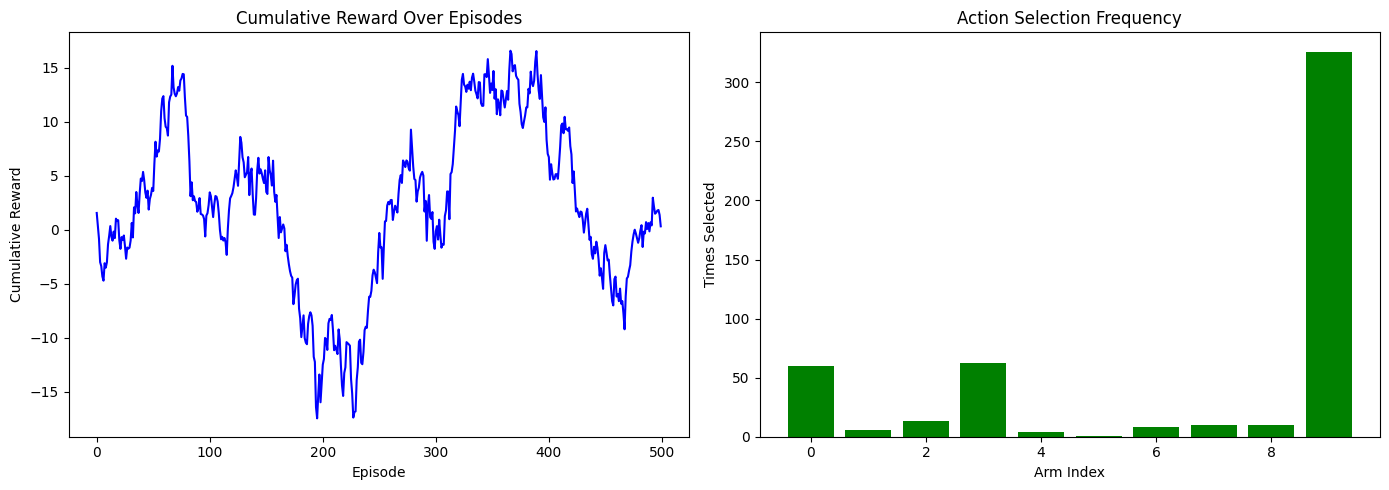

In [13]:
import matplotlib.pyplot as plt

plt. figure(figsize=(14, 5))

plt.subplot (1, 2, 1)
plt.plot(np.cumsum(all_rewards), color='blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")

plt.subplot (1, 2, 2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title("Action Selection Frequency")
plt.xlabel("Arm Index")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')